# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset dapat diperoleh dari berbagai sumber, seperti public repositories (*Kaggle*, *UCI ML Repository*, *Open Data*) atau data primer yang Anda kumpulkan sendiri.


# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

print("Seluruh library berhasil diimpor.")

Seluruh library berhasil diimpor.


# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [2]:
# Memuat dataset dari folder induk (satu tingkat di atas folder preprocessing)
raw_data_path = "../diabetes_raw.csv"
df = pd.read_csv(raw_data_path)

print(f"Ukuran dataset: {df.shape[0]} baris dan {df.shape[1]} kolom")
df.head()

Ukuran dataset: 768 baris dan 9 kolom


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

=== INFORMASI DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

=== STATISTIK DESKRIPTIF ===


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Jumlah data duplikat: 0
Jumlah missing values (NaN) per kolom:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Jumlah nilai 0 pada fitur medis:
- Glucose: 5 baris
- BloodPressure: 35 baris
- SkinThickness: 227 baris
- Insulin: 374 baris
- BMI: 11 baris


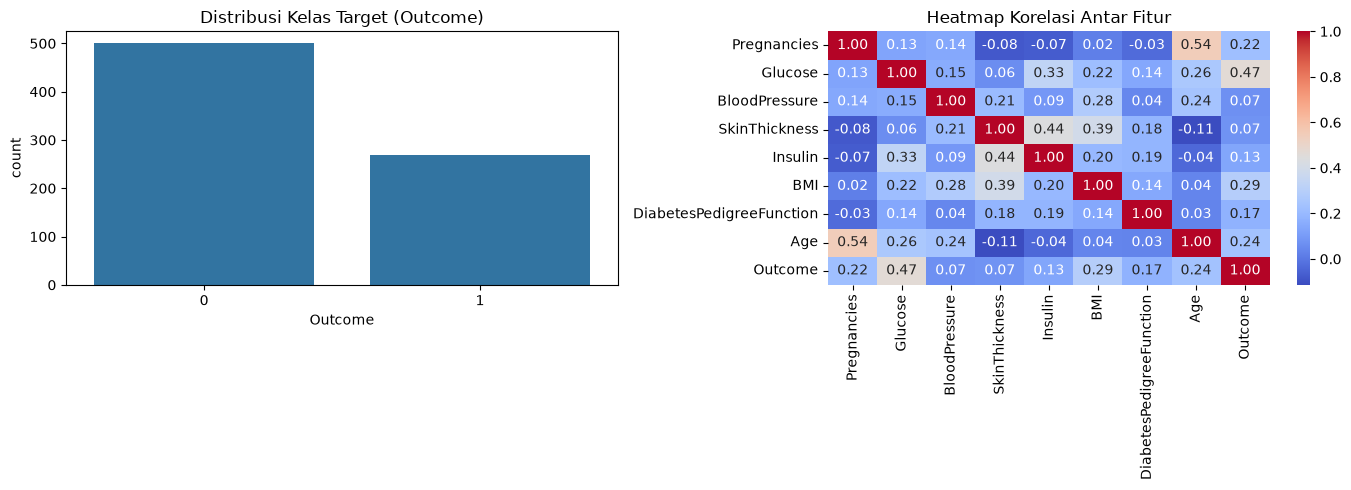

In [3]:
# 1. Informasi tipe data dan struktur dataset
print("=== INFORMASI DATASET ===")
print(df.info())

# 2. Statistik deskriptif
print("\n=== STATISTIK DESKRIPTIF ===")
display(df.describe())

# 3. Cek data duplikat dan missing values standar (NaN)
print(f"\nJumlah data duplikat: {df.duplicated().sum()}")
print("Jumlah missing values (NaN) per kolom:")
print(df.isnull().sum())

# 4. Cek nilai 0 yang tidak wajar secara medis (missing values tersembunyi)
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print("\nJumlah nilai 0 pada fitur medis:")
for col in zero_cols:
    print(f"- {col}: {(df[col] == 0).sum()} baris")

# 5. Visualisasi Distribusi Target dan Heatmap Korelasi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x='Outcome', data=df, ax=axes[0])
axes[0].set_title('Distribusi Kelas Target (Outcome)')

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('Heatmap Korelasi Antar Fitur')

plt.tight_layout()
plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

In [4]:
df_prep = df.copy()

# 1. Menghapus Data Duplikat
df_prep = df_prep.drop_duplicates()

# 2. Menangani Data Kosong (Mengganti nilai 0 tidak wajar dengan NaN, lalu imputasi dengan Median)
cols_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for col in cols_with_zero:
    df_prep[col] = df_prep[col].replace(0, np.nan)
    df_prep[col] = df_prep[col].fillna(df_prep[col].median())

# 3. Deteksi dan Penanganan Outlier menggunakan metode IQR Clipping
feature_cols = [c for c in df_prep.columns if c != 'Outcome']
for col in feature_cols:
    Q1 = df_prep[col].quantile(0.25)
    Q3 = df_prep[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_prep[col] = df_prep[col].clip(lower=lower_bound, upper=upper_bound)

# 4. Standarisasi Fitur menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_prep[feature_cols])

df_clean = pd.DataFrame(X_scaled, columns=feature_cols)
df_clean['Outcome'] = df_prep['Outcome'].values

# 5. Menyimpan Dataset Hasil Preprocessing
output_path = "diabetes_preprocessing.csv"
df_clean.to_csv(output_path, index=False)

print(f"Data preprocessing selesai! File disimpan di: {output_path} dengan ukuran {df_clean.shape}")
df_clean.head()

Data preprocessing selesai! File disimpan di: diabetes_preprocessing.csv dengan ukuran (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,0.647150,0.866045,-0.030632,0.824667,0.039062,0.181092,0.588927,1.445691,1
1,-0.848970,-1.205066,-0.543914,0.017945,0.039062,-0.869465,-0.378101,-0.189304,0
2,1.245598,2.016662,-0.715008,0.017945,0.039062,-1.364728,0.746595,-0.103252,1
3,-0.848970,-1.073567,-0.543914,-0.788777,-1.494110,-0.644346,-1.022787,-1.049828,0
4,-1.148194,0.504422,-2.768136,0.824667,1.414175,1.606849,2.596563,-0.017199,1
